# Face Mask Detection

A small face-mask classifier trained on real photos. The data is the Face Mask 12K Images dataset (originally posted on Kaggle by Ashish Jangra; I load the public Hugging Face mirror `DamarJati/Face-Mask-Detection`). The masked faces were scraped from image search and the unmasked ones come from the CelebA faces set, all already cropped to the face.

To keep this CPU-friendly I only read two of the twelve parquet row groups (the two that hold a mix of both classes), which gives about 1,800 face crops, resized to 48x48. Training is 3 epochs of a tiny two-layer CNN, so treat the numbers as a baseline, not a tuned model.

In [1]:
import io
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

torch.set_num_threads(2)
np.random.seed(11); torch.manual_seed(11)

In [2]:
# Face Mask 12K via the HF parquet export. Rows are mostly sorted by class, but the
# first and last row groups are mixed, so reading just those two gives a balanced sample.
fs = HfFileSystem()
PARQUET = "datasets/DamarJati/Face-Mask-Detection@refs%2Fconvert%2Fparquet/default/train/0000.parquet"
pf = pq.ParquetFile(fs.open(PARQUET))
rows = [pf.read_row_group(i).to_pandas() for i in (0, pf.metadata.num_row_groups - 1)]
import pandas as pd
raw = pd.concat(rows, ignore_index=True)

SIZE = 48
X = np.stack([
    np.asarray(Image.open(io.BytesIO(r["bytes"])).convert("RGB").resize((SIZE, SIZE)), dtype=np.float32) / 255.0
    for r in raw["image"]
])
# dataset labels: 0 = WithMask, 1 = WithoutMask. Flip so 1 means "mask" like the rest of the notebook.
labels = (1 - raw["label"].values).astype(np.int64)
print('faces:', X.shape, '| masked:', int(labels.sum()), 'of', len(labels))

faces: (1792, 48, 48, 3) | masked: 883 of 1792


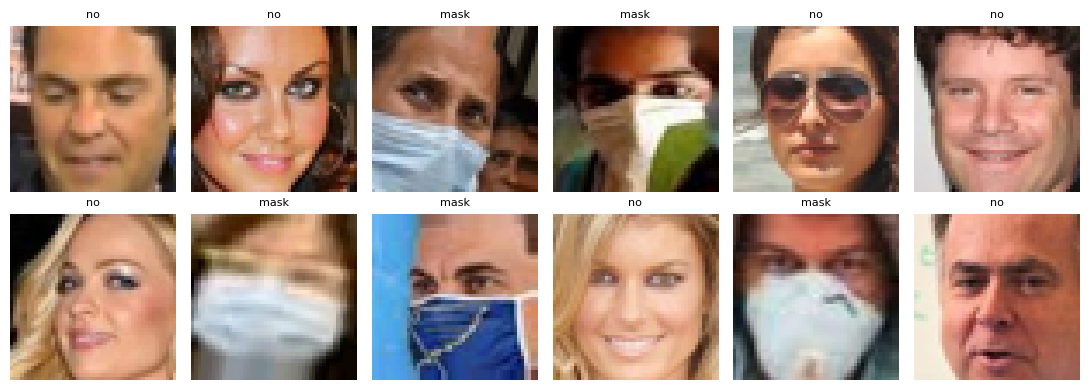

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.flat, np.random.choice(len(X), 12, replace=False)):
    ax.imshow(X[i]); ax.set_title('mask' if labels[i] == 1 else 'no', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
# tensors: (N,3,H,W)
Xt = torch.tensor(X).permute(0, 3, 1, 2).float()
yt = torch.tensor(labels)

Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=11)
Xtr_t = torch.tensor(Xtr); Xte_t = torch.tensor(Xte)
ytr_t = torch.tensor(ytr); yte_t = torch.tensor(yte)
print('train', Xtr_t.shape, 'test', Xte_t.shape)

train torch.Size([1433, 3, 48, 48]) test torch.Size([359, 3, 48, 48])


In [5]:
class MiniNet(nn.Module):
    def __init__(self, h, w):
        super().__init__()
        self.c1 = nn.Conv2d(3, 8, 5, padding=2)
        self.c2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        # compute fc size after two pools
        h2, w2 = h // 4, w // 4
        self.fc1 = nn.Linear(16 * h2 * w2, 32)
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

_, _, H, W = Xtr_t.shape
net = MiniNet(H, W)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

batch = 32
for ep in range(3):
    perm = torch.randperm(len(Xtr_t))
    losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = net(Xtr_t[idx])
        loss = F.cross_entropy(out, ytr_t[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=0.5767


epoch 1  mean_loss=0.3361


epoch 2  mean_loss=0.2553


In [6]:
net.eval()
with torch.no_grad():
    preds = net(Xte_t).argmax(1).numpy()

print(classification_report(yte, preds, target_names=['no_mask', 'mask']))
print('confusion:'); print(confusion_matrix(yte, preds))

              precision    recall  f1-score   support

     no_mask       0.87      0.98      0.93       182
        mask       0.98      0.85      0.91       177

    accuracy                           0.92       359
   macro avg       0.93      0.92      0.92       359
weighted avg       0.93      0.92      0.92       359

confusion:
[[179   3]
 [ 26 151]]


## Takeaways

On 359 held-out real face crops the tiny CNN gets 92% accuracy after 3 epochs. The errors are lopsided: it almost never calls an unmasked face masked (3 of 182), but it misses 26 of 177 masked faces. I haven't gone through the misses one by one yet; that's the first thing I'd do before changing the model.

Next steps I'd try: train on all 11.8K images instead of two row groups, add flips and color jitter, and put a face detector upstream (MediaPipe or OpenCV DNN) so the model can run on full photos rather than pre-cropped faces. The 12K set is also fairly clean and front-facing, so I'd expect a drop on CCTV-style footage.